Shape: (178, 13)

eps = 2.3, min_samples = 4
Number of clusters : 2
Number of noise points : 36
Largest cluster size : 99
Silhouette (non-noise) : 0.3254
Core points : 113

Effect of eps and min_samples:
 eps min_samples clusters noise
 1.8  4 9 103
 1.8  8 1 170
 2.0  4 6  66
 2.0  8 3 117
 2.3  4 2  36
 2.3  8 2  52
 2.6  4 1  20
 2.6  8 1  25
 3.0  4 1  11
 3.0  8 1  11


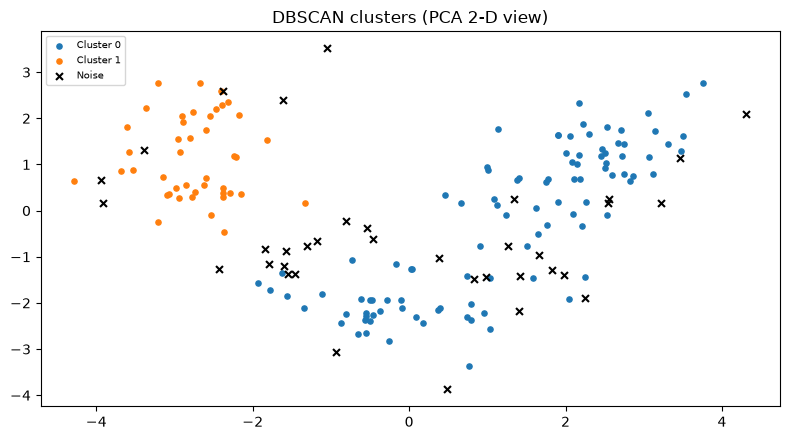

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

wine = load_wine()
X = StandardScaler().fit_transform(wine.data)
print("Shape:", X.shape)

db = DBSCAN(eps=2.3, min_samples=4).fit(X)
labels = db.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
mask = labels != -1

print("\neps = 2.3, min_samples = 4")
print("Number of clusters :", n_clusters)
print("Number of noise points :", n_noise)
print("Largest cluster size :", pd.Series(labels[mask]).value_counts().max())
print("Silhouette (non-noise) : %.4f" % silhouette_score(X[mask], labels[mask]))
print("Core points :", len(db.core_sample_indices_))

print("\nEffect of eps and min_samples:")
print(" eps min_samples clusters noise")
for eps in [1.8, 2.0, 2.3, 2.6, 3.0]:
    for ms in [4, 8]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        print(" %.1f %2d %d %3d" % (eps, ms, len(set(l)) - (1 if -1 in l else 0), (l == -1).sum()))

P = PCA(2).fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 4.5))
for c in range(n_clusters):
    ax.scatter(P[labels == c, 0], P[labels == c, 1], s=14, label="Cluster %d" % c)
ax.scatter(P[labels == -1, 0], P[labels == -1, 1], s=25, marker="x", color="black", label="Noise")
ax.set_title("DBSCAN clusters (PCA 2-D view)")
ax.legend(fontsize=7)
plt.tight_layout()